[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcosta/generative-networks/blob/main/diffusion/diffusion.ipynb)

This notebook is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).


# Training a Diffusion Model on MNIST

Tutorial for training a small denoising diffusion model to generate MNIST-like handwritten digits.

A diffusion model has two processes:

- The **forward process** gradually adds Gaussian noise to an image until it becomes nearly pure noise.
- The **reverse process** starts from noise and repeatedly denoises it to produce an image.

In this notebook we train a DDPM-style model. At each training step we choose a random timestep `t`, add the exact amount of noise for that timestep, and train a neural network to predict the noise that was added.


## 0. Dependencies


In [1]:
# Install the packages used by this notebook.
# In Colab and many course environments these are already installed, so this cell usually just prints a confirmation.
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
}

missing = [
    pip_name
    for import_name, pip_name in packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")


All required packages are already installed.


## 1. Imports and Reproducibility


In [2]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


## 2. Configuration

The defaults are small enough for a tutorial. More epochs, more diffusion steps, and a wider U-Net usually improve generated digits.


In [3]:
project_root = Path.cwd().parent if Path.cwd().name == "diffusion" else Path.cwd()
data_dir = project_root / "data"
output_dir = project_root / "diffusion" / "outputs" / "mnist_diffusion"
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 128
image_channels = 1
image_size = 28
base_channels = 32
time_embedding_dim = 128
num_timesteps = 100
beta_start = 1e-4
beta_end = 2e-2
epochs = 20
learning_rate = 2e-4

sample_every_epochs = 5
checkpoint_path = output_dir / "mnist_diffusion_checkpoint.pt"


## 3. Load MNIST

Diffusion models usually work with centered image values. We transform MNIST from `[0, 1]` into `[-1, 1]`, then convert generated images back to `[0, 1]` for display.


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(), # Convert PIL image to tensor and scale pixel values to [0, 1].
    transforms.Normalize(mean=(0.5,), std=(0.5,)), # Scale pixel values to [-1, 1].
])

train_dataset = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root=data_dir,
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

len(train_dataset), len(train_loader), len(test_dataset), len(test_loader)


/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


(60000, 469, 10000, 79)

Let's inspect a batch of real MNIST images.


/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


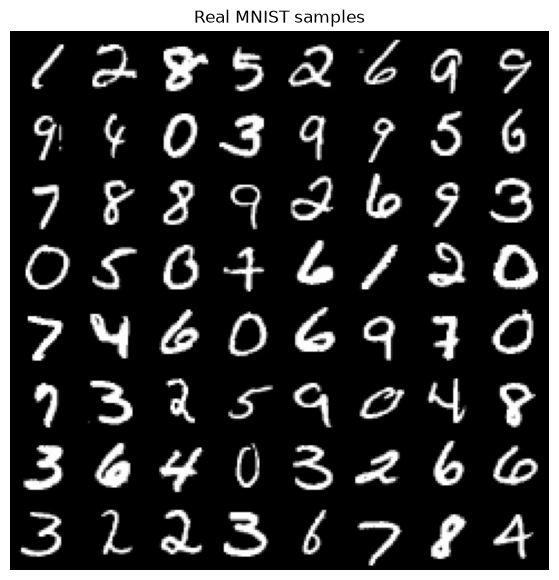

In [5]:
def denormalize(images):
    return (images + 1) / 2


def show_image_grid(images, title=None, nrow=8):
    images = denormalize(images.detach().cpu()).clamp(0, 1)
    grid = make_grid(images, nrow=nrow, padding=2)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


real_images, real_labels = next(iter(train_loader))
show_image_grid(real_images[:64], title="Real MNIST samples")


## 4. Diffusion Noise Schedule

The forward process uses a sequence of variances `beta_t`. Small `beta_t` values add a little noise at each step, and the cumulative product of `alpha_t = 1 - beta_t` tells us how much of the original image remains at timestep `t`.

The nice part is that we do not need to apply noise one step at a time during training. We can sample directly from:

`q(x_t | x_0) = sqrt(alpha_bar_t) x_0 + sqrt(1 - alpha_bar_t) epsilon`

where `epsilon` is standard Gaussian noise.


In [6]:
betas = torch.linspace(beta_start, beta_end, num_timesteps, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_previous = F.pad(alpha_bars[:-1], (1, 0), value=1.0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
posterior_variance = betas * (1.0 - alpha_bars_previous) / (1.0 - alpha_bars)


def extract(values, timesteps, x_shape):
    batch_size_seen = timesteps.shape[0]
    gathered = values.gather(0, timesteps)
    return gathered.reshape(batch_size_seen, *((1,) * (len(x_shape) - 1)))


def q_sample(x_start, timesteps, noise=None):
    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha_bar_t = extract(sqrt_alpha_bars, timesteps, x_start.shape)
    sqrt_one_minus_alpha_bar_t = extract(sqrt_one_minus_alpha_bars, timesteps, x_start.shape)
    return sqrt_alpha_bar_t * x_start + sqrt_one_minus_alpha_bar_t * noise


## 5. Visualize the Forward Process

Here we take one clean digit and apply the closed-form forward process at several timesteps. Early images keep most of the digit structure; late images should look close to Gaussian noise.


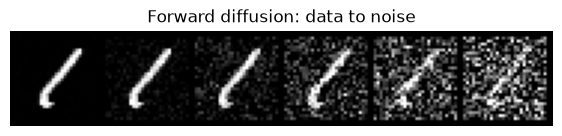

In [7]:
@torch.no_grad()
def show_forward_diffusion(images, timesteps):
    image = images[:1].to(device)
    noised_images = []

    for timestep in timesteps:
        t = torch.tensor([timestep], device=device, dtype=torch.long)
        noised_images.append(q_sample(image, t))

    noised_images = torch.cat(noised_images, dim=0)
    show_image_grid(noised_images, title="Forward diffusion: data to noise", nrow=len(timesteps))


forward_timesteps = [0, 10, 25, 50, 75, num_timesteps - 1]
show_forward_diffusion(real_images, forward_timesteps)


## 6. Time Embeddings

The denoising network must know which timestep it is seeing. We encode `t` with sinusoidal features, then pass those features through a small MLP before injecting them into the convolutional blocks.


In [8]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2
        frequencies = torch.exp(
            torch.arange(half_dim, device=timesteps.device)
            * (-math.log(10000) / (half_dim - 1))
        )
        angles = timesteps[:, None] * frequencies[None, :]
        embedding = torch.cat([torch.sin(angles), torch.cos(angles)], dim=-1)

        if self.embedding_dim % 2 == 1:
            embedding = F.pad(embedding, (0, 1))

        return embedding


## 7. Define the Denoising U-Net

The network receives a noisy image `x_t` and a timestep `t`, then predicts the Gaussian noise `epsilon` that was added to the clean image.

This is a compact U-Net: the encoder lowers spatial resolution from `28 x 28` to `14 x 14` to `7 x 7`, the middle block processes low-resolution features, and the decoder upsamples while using skip connections from the encoder.


In [9]:
def num_groups(channels):
    return 8 if channels % 8 == 0 else 1


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.norm1 = nn.GroupNorm(num_groups(out_channels), out_channels)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.norm2 = nn.GroupNorm(num_groups(out_channels), out_channels)
        self.residual = (
            nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, time_embedding):
        h = self.conv1(x)
        h = self.norm1(h)
        h = h + self.time_projection(time_embedding)[:, :, None, None]
        h = F.silu(h)
        h = self.conv2(h)
        h = self.norm2(h)
        h = F.silu(h)
        return h + self.residual(x)


class DenoisingUNet(nn.Module):
    def __init__(self, image_channels=1, base_channels=32, time_dim=128, num_timesteps=100):
        super().__init__()
        self.num_timesteps = num_timesteps
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

        self.initial = nn.Conv2d(image_channels, base_channels, kernel_size=3, padding=1)

        self.down_block1 = ResidualBlock(base_channels, base_channels, time_dim)
        self.downsample1 = nn.Conv2d(base_channels, base_channels * 2, kernel_size=4, stride=2, padding=1)
        self.down_block2 = ResidualBlock(base_channels * 2, base_channels * 2, time_dim)
        self.downsample2 = nn.Conv2d(base_channels * 2, base_channels * 4, kernel_size=4, stride=2, padding=1)

        self.middle = ResidualBlock(base_channels * 4, base_channels * 4, time_dim)

        self.upsample2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, kernel_size=4, stride=2, padding=1)
        self.up_block2 = ResidualBlock(base_channels * 4, base_channels * 2, time_dim)
        self.upsample1 = nn.ConvTranspose2d(base_channels * 2, base_channels, kernel_size=4, stride=2, padding=1)
        self.up_block1 = ResidualBlock(base_channels * 2, base_channels, time_dim)

        self.output = nn.Sequential(
            nn.GroupNorm(num_groups(base_channels), base_channels),
            nn.SiLU(),
            nn.Conv2d(base_channels, image_channels, kernel_size=3, padding=1),
        )

    def forward(self, x, timesteps):
        scaled_timesteps = timesteps.float() / (self.num_timesteps - 1)
        time_embedding = self.time_mlp(scaled_timesteps)

        x = self.initial(x)
        skip1 = self.down_block1(x, time_embedding)
        x = self.downsample1(skip1)
        skip2 = self.down_block2(x, time_embedding)
        x = self.downsample2(skip2)

        x = self.middle(x, time_embedding)

        x = self.upsample2(x)
        x = torch.cat([x, skip2], dim=1)
        x = self.up_block2(x, time_embedding)
        x = self.upsample1(x)
        x = torch.cat([x, skip1], dim=1)
        x = self.up_block1(x, time_embedding)

        return self.output(x)


## 8. Initialize Model and Optimizer

This U-Net is intentionally small so that the full notebook remains practical. It will not match a large image diffusion model, but the training objective and sampling equations are the same DDPM idea.


In [10]:
denoiser = DenoisingUNet(
    image_channels=image_channels,
    base_channels=base_channels,
    time_dim=time_embedding_dim,
    num_timesteps=num_timesteps,
).to(device)
optimizer = torch.optim.AdamW(denoiser.parameters(), lr=learning_rate)

print(denoiser)


DenoisingUNet(
  (time_mlp): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=128, out_features=128, bias=True)
    (2): SiLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
  )
  (initial): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down_block1): ResidualBlock(
    (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (time_projection): Linear(in_features=128, out_features=32, bias=True)
    (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm2): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (residual): Identity()
  )
  (downsample1): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (down_block2): ResidualBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    (time_project

## 9. Reverse Sampling and Checkpoint Helpers

To generate images, start from Gaussian noise at the final timestep and repeatedly apply one learned denoising step. Each step uses the network prediction to estimate the mean of the reverse transition.


In [11]:
@torch.no_grad()
def p_sample(model, x, timestep):
    batch_size_seen = x.size(0)
    timesteps = torch.full((batch_size_seen,), timestep, device=device, dtype=torch.long)

    beta_t = extract(betas, timesteps, x.shape)
    sqrt_one_minus_alpha_bar_t = extract(sqrt_one_minus_alpha_bars, timesteps, x.shape)
    sqrt_recip_alpha_t = extract(sqrt_recip_alphas, timesteps, x.shape)

    predicted_noise = model(x, timesteps)
    model_mean = sqrt_recip_alpha_t * (x - beta_t * predicted_noise / sqrt_one_minus_alpha_bar_t)

    if timestep == 0:
        return model_mean

    variance_t = extract(posterior_variance, timesteps, x.shape)
    return model_mean + torch.sqrt(variance_t) * torch.randn_like(x)


@torch.no_grad()
def sample(model, num_samples=64):
    model.eval()
    x = torch.randn(num_samples, image_channels, image_size, image_size, device=device)

    for timestep in reversed(range(num_timesteps)):
        x = p_sample(model, x, timestep)

    return x.clamp(-1, 1)


@torch.no_grad()
def sample_images(model, num_samples=64, title="Generated samples", save_path=None):
    images = sample(model, num_samples=num_samples)

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        grid = make_grid(denormalize(images.detach().cpu()).clamp(0, 1), nrow=8, padding=2)
        plt.imsave(save_path, grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")

    show_image_grid(images, title=title, nrow=8)
    return images


def save_checkpoint(epoch, history):
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": denoiser.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "config": {
                "image_channels": image_channels,
                "image_size": image_size,
                "base_channels": base_channels,
                "time_embedding_dim": time_embedding_dim,
                "num_timesteps": num_timesteps,
                "beta_start": beta_start,
                "beta_end": beta_end,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
            },
        },
        checkpoint_path,
    )


## 10. Diffusion Training Step

Training is supervised because we know the exact noise that we added.

For each batch:

1. Sample a random timestep `t` for every image.
2. Sample Gaussian noise `epsilon`.
3. Construct the noisy image `x_t` with the closed-form forward process.
4. Train the U-Net to predict `epsilon` from `(x_t, t)`.


In [12]:
def diffusion_loss(model, images):
    batch_size_seen = images.size(0)
    timesteps = torch.randint(0, num_timesteps, (batch_size_seen,), device=device)
    noise = torch.randn_like(images)
    noisy_images = q_sample(images, timesteps, noise=noise)
    predicted_noise = model(noisy_images, timesteps)
    return F.mse_loss(predicted_noise, noise)


def run_epoch(model, data_loader, train=True):
    model.train(train)
    total_loss = 0.0
    total_images = 0

    for images, _ in data_loader:
        images = images.to(device, non_blocking=True)

        if train:
            optimizer.zero_grad(set_to_none=True)
            loss = diffusion_loss(model, images)
            loss.backward()
            optimizer.step()
        else:
            with torch.no_grad():
                loss = diffusion_loss(model, images)

        batch_size_seen = images.size(0)
        total_loss += loss.item() * batch_size_seen
        total_images += batch_size_seen

    return total_loss / total_images


def train_one_epoch(epoch, model, train_loader, test_loader):
    train_loss = run_epoch(model, train_loader, train=True)
    test_loss = run_epoch(model, test_loader, train=False)

    return {
        "epoch": epoch,
        "train_loss": train_loss,
        "test_loss": test_loss,
    }


## 11. Train the Diffusion Model

Run this cell to train. The loss measures noise-prediction error; lower usually means the denoiser is learning, but generated samples are the most important qualitative check.

Sampling is slower than in the GAN or VAE notebooks because one generated image requires many denoising steps.


Epoch 001/020 | train loss: 0.1685 | test loss: 0.0985
Epoch 002/020 | train loss: 0.0887 | test loss: 0.0835
Epoch 003/020 | train loss: 0.0781 | test loss: 0.0759
Epoch 004/020 | train loss: 0.0727 | test loss: 0.0696
Epoch 005/020 | train loss: 0.0692 | test loss: 0.0696


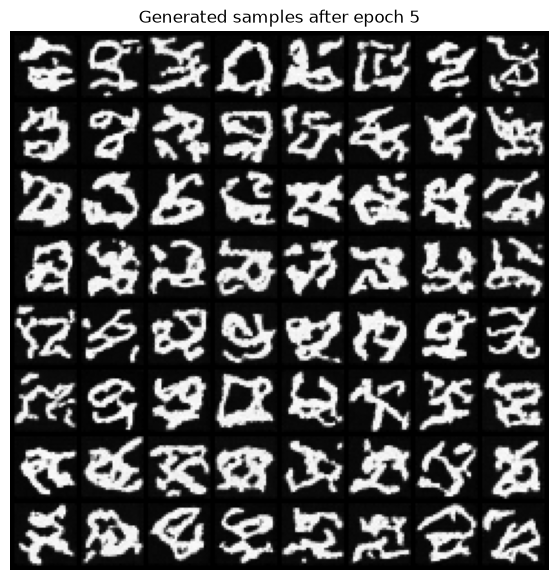

Epoch 006/020 | train loss: 0.0666 | test loss: 0.0649
Epoch 007/020 | train loss: 0.0649 | test loss: 0.0626
Epoch 008/020 | train loss: 0.0641 | test loss: 0.0619
Epoch 009/020 | train loss: 0.0622 | test loss: 0.0626
Epoch 010/020 | train loss: 0.0621 | test loss: 0.0630


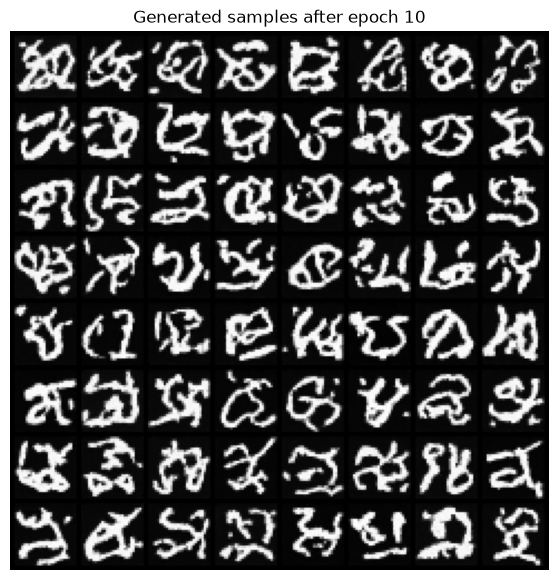

Epoch 011/020 | train loss: 0.0607 | test loss: 0.0607
Epoch 012/020 | train loss: 0.0601 | test loss: 0.0635
Epoch 013/020 | train loss: 0.0600 | test loss: 0.0582
Epoch 014/020 | train loss: 0.0593 | test loss: 0.0582
Epoch 015/020 | train loss: 0.0588 | test loss: 0.0579


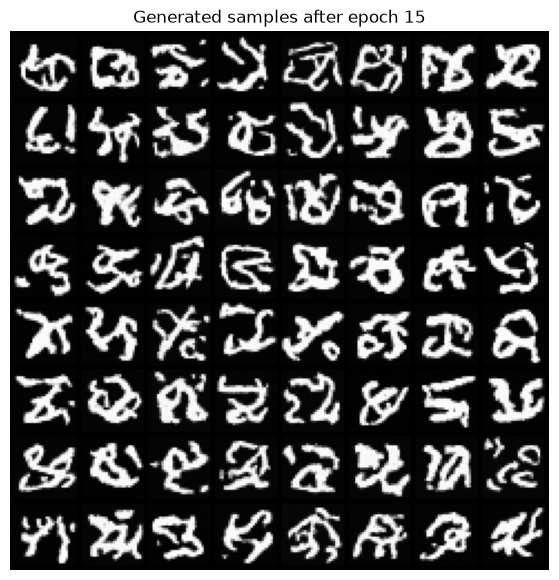

Epoch 016/020 | train loss: 0.0583 | test loss: 0.0581
Epoch 017/020 | train loss: 0.0583 | test loss: 0.0585
Epoch 018/020 | train loss: 0.0579 | test loss: 0.0566
Epoch 019/020 | train loss: 0.0575 | test loss: 0.0571
Epoch 020/020 | train loss: 0.0574 | test loss: 0.0562


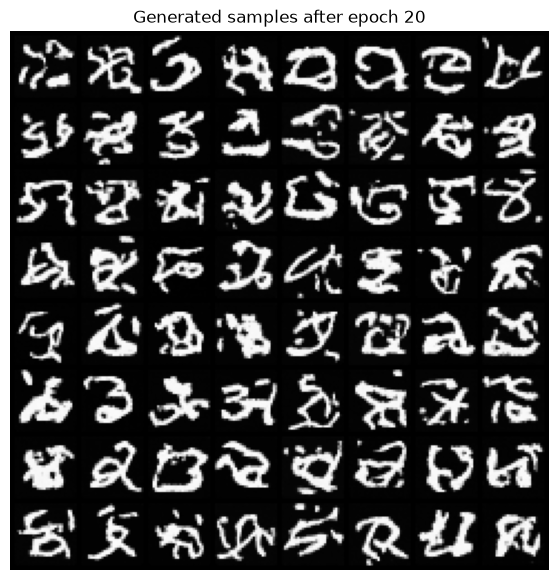

Saved latest checkpoint to: /home/nahuel/generative-networks/diffusion/outputs/mnist_diffusion/mnist_diffusion_checkpoint.pt


In [13]:
history = []

for epoch in range(1, epochs + 1):
    metrics = train_one_epoch(epoch, denoiser, train_loader, test_loader)
    history.append(metrics)

    print(
        f"Epoch {epoch:03d}/{epochs:03d} | "
        f"train loss: {metrics['train_loss']:.4f} | "
        f"test loss: {metrics['test_loss']:.4f}"
    )

    if epoch % sample_every_epochs == 0 or epoch == epochs:
        sample_path = output_dir / f"samples_epoch_{epoch:03d}.png"
        sample_images(denoiser, title=f"Generated samples after epoch {epoch}", save_path=sample_path)

    save_checkpoint(epoch, history)

print(f"Saved latest checkpoint to: {checkpoint_path}")


## 12. Plot Training Curves

The DDPM objective is a noise-prediction regression loss. It is usually meaningful to track whether it decreases over time.


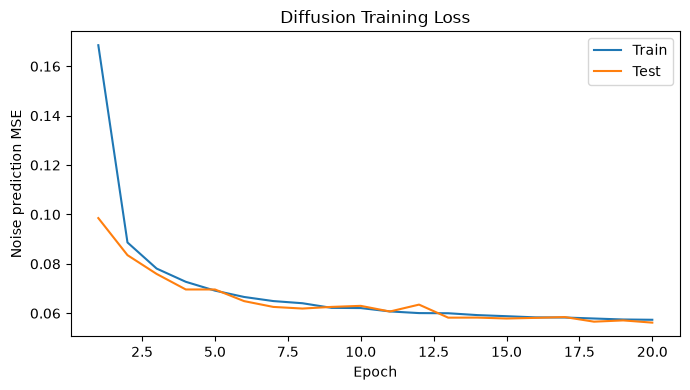

In [14]:
epochs_seen = [row["epoch"] for row in history]

plt.figure(figsize=(7, 4))
plt.plot(epochs_seen, [row["train_loss"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_loss"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("Noise prediction MSE")
plt.legend()
plt.title("Diffusion Training Loss")
plt.tight_layout()
plt.show()


## 13. Generate New Digits

After training, we sample pure Gaussian noise and apply the learned reverse diffusion process from the last timestep back to zero.


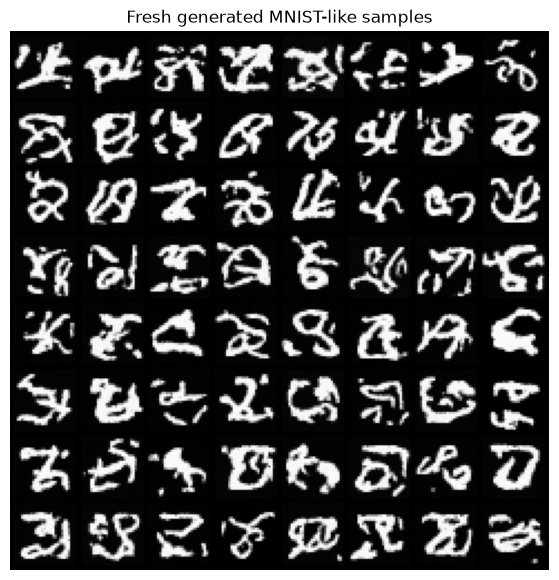

tensor([[[[-0.9549, -0.9643, -0.9596,  ..., -0.9698, -0.9712, -0.9656],
          [-0.9682, -0.9685, -0.9714,  ..., -0.9685, -0.9695, -0.9709],
          [-0.9693, -0.9627, -0.9670,  ..., -0.9680, -0.9731, -0.9706],
          ...,
          [-0.9759, -0.9721, -0.9707,  ..., -0.9594, -0.9601, -0.9759],
          [-0.9741, -0.9695, -0.9671,  ..., -0.9671, -0.9669, -0.9544],
          [-0.9951, -0.9705, -0.9752,  ..., -0.9675, -0.9729, -0.9891]]],


        [[[-0.9731, -0.9809, -0.9778,  ..., -0.9807, -0.9778, -0.9790],
          [-0.9746, -0.9828, -0.9818,  ..., -0.9830, -0.9811, -0.9802],
          [-0.9755, -0.9789, -0.9812,  ..., -0.9819, -0.9822, -0.9853],
          ...,
          [-0.9859, -0.9800, -0.9827,  ..., -0.9842, -0.9845, -0.9824],
          [-0.9806, -0.9800, -0.9806,  ..., -0.9759, -0.9792, -0.9791],
          [-0.9828, -0.9831, -0.9854,  ..., -0.9819, -0.9829, -0.9707]]],


        [[[-0.9790, -0.9659, -0.9578,  ..., -0.9750, -0.9769, -0.9678],
          [-0.9800, -0.974

In [ ]:
sample_images(denoiser, title="Fresh generated MNIST-like samples")

## 14. Visualize the Sampling Trajectory

This cell records a single sample while it moves through the reverse process. The first image is close to noise; later images should become more digit-like.


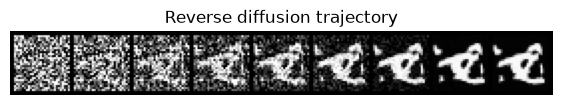

In [16]:
@torch.no_grad()
def visualize_sampling_trajectory(model, num_snapshots=8):
    model.eval()
    x = torch.randn(1, image_channels, image_size, image_size, device=device)
    snapshot_timesteps = set(
        torch.linspace(num_timesteps - 1, 0, num_snapshots, dtype=torch.long).tolist()
    )
    snapshots = []

    for timestep in reversed(range(num_timesteps)):
        if timestep in snapshot_timesteps:
            snapshots.append(x.clone())
        x = p_sample(model, x, timestep)

    snapshots.append(x.clone())
    snapshots = torch.cat(snapshots, dim=0)
    show_image_grid(snapshots, title="Reverse diffusion trajectory", nrow=snapshots.size(0))


visualize_sampling_trajectory(denoiser)


## 15. Denoise a Test Image

We can also start from a real image, add noise at a chosen timestep, and run the learned reverse process from that point. This is not how unconditional generation starts, but it is a useful way to inspect what the denoiser has learned.


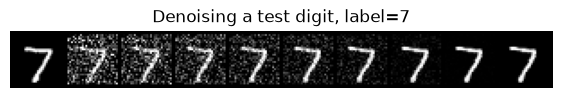

In [17]:
@torch.no_grad()
def denoise_test_image(model, start_timestep=75, num_snapshots=8):
    model.eval()
    test_images, test_labels = next(iter(test_loader))
    clean_image = test_images[:1].to(device)
    timestep = torch.tensor([start_timestep], device=device, dtype=torch.long)
    x = q_sample(clean_image, timestep)

    snapshot_timesteps = set(
        torch.linspace(start_timestep, 0, num_snapshots, dtype=torch.long).tolist()
    )
    snapshots = [clean_image]

    for current_timestep in reversed(range(start_timestep + 1)):
        if current_timestep in snapshot_timesteps:
            snapshots.append(x.clone())
        x = p_sample(model, x, current_timestep)

    snapshots.append(x.clone())
    snapshots = torch.cat(snapshots, dim=0)
    show_image_grid(
        snapshots,
        title=f"Denoising a test digit, label={test_labels[0].item()}",
        nrow=snapshots.size(0),
    )


denoise_test_image(denoiser)


## 16. Loading a Saved Checkpoint

Use this cell later if you restart the kernel and want to resume from the latest saved model.


In [ ]:
# checkpoint = torch.load(checkpoint_path, map_location=device)
# denoiser.load_state_dict(checkpoint["model_state_dict"])
# optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
# history = checkpoint["history"]
# print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")


## 17. Things to Try

- Increase `epochs` and compare sample quality against the GAN, VAE, and flow notebooks.
- Increase `num_timesteps` for a smoother reverse process, then notice how sampling time changes.
- Increase `base_channels` to make the U-Net more expressive.
- Replace the linear beta schedule with a cosine schedule.
- Condition the denoiser on digit labels to generate a chosen number.


## Troubleshooting

- If generated samples look like noise, train longer or increase `base_channels`.
- If sampling is slow, lower `num_timesteps` while experimenting.
- If training is unstable, lower `learning_rate` or use gradient clipping.
- If you run out of GPU memory, lower `batch_size` or `base_channels`.
